In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [5]:
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [6]:
df = df.fillna(0)

In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
target = 'fuel_efficiency_mpg'
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

In [9]:
df_train = df_train.drop(columns=target)
df_val = df_val.drop(columns=target)
df_test = df_test.drop(columns=target)

In [10]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))
X_test = dv.transform(df_test.to_dict(orient='records'))

In [11]:
from sklearn.tree import DecisionTreeRegressor, export_text

In [12]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [13]:
feature_names = list(dv.get_feature_names_out())
print(export_text(dt, feature_names=feature_names))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

In [15]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

,n_estimators,10
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
y_pred = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)

In [18]:
print(round(rmse, 4))

1.8371


In [19]:
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    print(n, round(root_mean_squared_error(y_val, y_pred), 3))

10 1.837
50 1.772
100 1.768
150 1.769


In [20]:
import numpy as np

In [21]:
for d in [10, 15, 20, 25]:
    scores = []
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=d,random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        scores.append(root_mean_squared_error(y_val, y_pred))

    print(d, round(np.mean(scores), 4))

10 1.7554
15 1.784
20 1.7882
25 1.7863


In [22]:
import matplotlib.pyplot as plt

In [24]:
depths = [10, 15, 20, 25]
n_values = [10, 50, 100, 150]

In [25]:
results = {}   # max_depth -> list of RMSEs, one per n_estimators

for d in depths:
    scores = []
    for n in n_values:
        rf = RandomForestRegressor(n_estimators=n, max_depth=d,
                                   random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        scores.append(root_mean_squared_error(y_val, y_pred))
    results[d] = scores
    print(d, round(np.mean(scores), 4))


10 1.7554
15 1.784
20 1.7882
25 1.7863


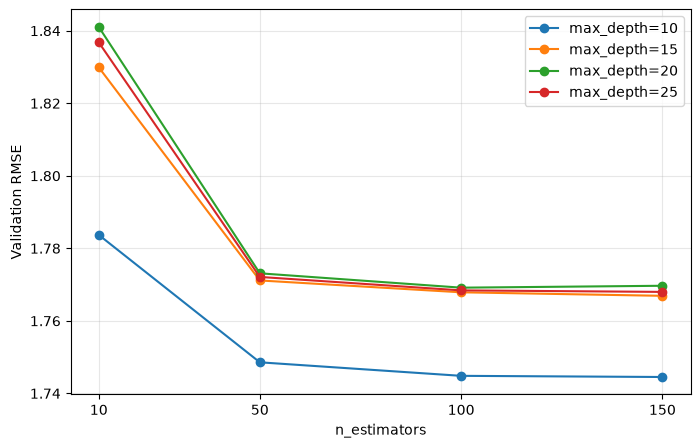

In [28]:
plt.figure(figsize=(8, 5))
for d in depths:
    plt.plot(n_values, results[d], marker='o', label=f'max_depth={d}')

plt.xlabel('n_estimators')
plt.ylabel('Validation RMSE')
plt.xticks(n_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_,
                        index=dv.get_feature_names_out())

print(importances.sort_values(ascending=False))

model_year                      0.296001
vehicle_weight                  0.203879
fuel_type=Gasoline              0.160712
horsepower                      0.078017
engine_displacement             0.061005
acceleration                    0.055201
origin=USA                      0.042144
drivetrain=Front-wheel drive    0.020145
num_doors                       0.019415
fuel_type=Diesel                0.017038
fuel_type=Hybrid                0.015800
drivetrain=All-wheel drive      0.007682
num_cylinders                   0.007284
origin=Asia                     0.006391
drivetrain=Rear-wheel drive     0.005781
origin=Europe                   0.003505
dtype: float64


In [33]:
%pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB 487.6 kB/s eta 0:03:29
   ---------------------------------------- 0.1/101.7 MB 1.0 MB/s eta 0:01:40
   ---------------------------------------- 0.3/101.7 MB 1.8 MB/s eta 0:00:58
   ---------------------------------------- 0.4/101.7 MB 2.2 MB/s eta 0:00:46
   ---------------------------------------- 0.9/101.7 MB 3.4 MB/s eta 0:00:30
    --------------------------------------- 1.7/101.7 MB 6.1 MB/s eta 0:00:17
   - -------------------------------------- 3.5/101.7 MB 10.7 MB/s eta 0:00:10
   -- ------------------------------------- 5.8/101.7 MB 15.4 MB/s eta 0:00:07
   --- ------------------------------------ 8.0/101.7 MB 19.0 MB/s eta 0:00:05
   --- ------------------------------------ 8.0/101.7 MB 18.3 MB/s eta 0:00:06
   --- ------------------------------------ 8.1/101.7 MB 15.7 MB/s eta 0


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import xgboost as xgb

In [35]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]


In [37]:
    xgb_params = {
        'eta': 0.3,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }
    model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                      evals=watchlist, verbose_eval=10)

[0]	train-rmse:2.40653	val-rmse:2.46782
[10]	train-rmse:1.47125	val-rmse:1.73205
[20]	train-rmse:1.39368	val-rmse:1.73766
[30]	train-rmse:1.33243	val-rmse:1.74548
[40]	train-rmse:1.25326	val-rmse:1.76296
[50]	train-rmse:1.18645	val-rmse:1.77517
[60]	train-rmse:1.10265	val-rmse:1.79401
[70]	train-rmse:1.04604	val-rmse:1.80444
[80]	train-rmse:0.99487	val-rmse:1.81308
[90]	train-rmse:0.94986	val-rmse:1.82135
[99]	train-rmse:0.90106	val-rmse:1.82646


In [38]:
    xgb_params = {
        'eta': 0.1,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }
    model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                      evals=watchlist, verbose_eval=10)

[0]	train-rmse:2.74739	val-rmse:2.78635
[10]	train-rmse:1.80592	val-rmse:1.93152
[20]	train-rmse:1.55847	val-rmse:1.75076
[30]	train-rmse:1.47544	val-rmse:1.71667
[40]	train-rmse:1.43074	val-rmse:1.71289
[50]	train-rmse:1.40368	val-rmse:1.71358
[60]	train-rmse:1.37884	val-rmse:1.71688
[70]	train-rmse:1.36283	val-rmse:1.71919
[80]	train-rmse:1.34578	val-rmse:1.72100
[90]	train-rmse:1.32546	val-rmse:1.72303
[99]	train-rmse:1.31192	val-rmse:1.72481
